In [ ]:
# script for downloading NASA GEX-NDDP data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import os
import warnings
warnings.filterwarnings('ignore')
from urllib.parse import urlencode, urljoin
from urllib.request import urlopen

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt
import xarray as xr

## Change path to correct data directory

In [2]:
! pwd

/Users/tedscott/Google Drive/My Drive/PhD Work/Codes/HeatWaves/HeatWaves


In [3]:
# example URL: https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/CESM2/historical/r4i1p1f1/tas/tas_day_CESM2_historical_r4i1p1f1_gn_1962_v2.0.nc
os.chdir('../../../Data/CMIP6/NEX-GDDP-CMIP6/BCC-CSM2-MR/raw')
! ls -al

total 16
drwxr-xr-x@ 3 tedscott  staff    96 Oct 15 08:51 .
drwxr-xr-x@ 5 tedscott  staff   160 Oct  9 15:21 ..
-rw-r--r--@ 1 tedscott  staff  6148 Oct 15 08:51 .DS_Store


## Download files

In [7]:
# try downloading to local drive to see if this is faster?
#os.chdir('/Users/tedscott/Downloads/CMIP6-downloads/')

In [18]:
process_yrs = np.arange(2034,2101,1)
#process_yrs = [2016]
process_yrs

array([2034, 2035, 2036, 2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044,
       2045, 2046, 2047, 2048, 2049, 2050, 2051, 2052, 2053, 2054, 2055,
       2056, 2057, 2058, 2059, 2060, 2061, 2062, 2063, 2064, 2065, 2066,
       2067, 2068, 2069, 2070, 2071, 2072, 2073, 2074, 2075, 2076, 2077,
       2078, 2079, 2080, 2081, 2082, 2083, 2084, 2085, 2086, 2087, 2088,
       2089, 2090, 2091, 2092, 2093, 2094, 2095, 2096, 2097, 2098, 2099,
       2100])

In [19]:
%%time
# taking roughly 9 min per file on 2026-10-06
# help from https://realpython.com/python-download-file-from-url/#downloading-a-large-file-in-a-streaming-fashion

scenario = "ssp370"#"historical"#"ssp245"
realization = "r1i1p1f1"#"r4i1p1f1"
model = "BCC-CSM2-MR"#"CanESM5"#"CESM2"
grid = "gn"#"gr1"#"gn"

for yr in process_yrs:

    start = dt.now()
    
    filename = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    url = "https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/"+model+"/"+scenario+"/"+realization+"/tas/"+filename
    response = requests.get(url, stream=True)
    response.headers

    with open(filename, mode="wb") as file:
        for chunk in response.iter_content():
            file.write(chunk)
            
    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")


Time for 2034 :9.109032633333333 min
CPU times: user 8min 59s, sys: 2.63 s, total: 9min 1s
Wall time: 10min 22s


ConnectTimeout: HTTPSConnectionPool(host='ds.nccs.nasa.gov', port=443): Max retries exceeded with url: /thredds/fileServer/AMES/NEX/GDDP-CMIP6/BCC-CSM2-MR/ssp370/r1i1p1f1/tas/tas_day_BCC-CSM2-MR_ssp370_r1i1p1f1_gn_2035_v2.0.nc (Caused by ConnectTimeoutError(<HTTPSConnection(host='ds.nccs.nasa.gov', port=443) at 0x111658cd0>, 'Connection to ds.nccs.nasa.gov timed out. (connect timeout=None)'))

## Use CDO to regrid to match ERA5 and fix time variable

### using os.system() calls to cdo

In [12]:
process_yrs = np.arange(1961,2015,1)
scenario = "historical"

In [13]:
%%time

for yr in process_yrs:
    start = dt.now()

    # change grid to match ERA5
    cmd = "remapbil,r1440x721"
    infile = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    os.system("cdo "+cmd+" "+infile+" "+outfile)

    # set longitude range
    cmd2 = "-sellonlatbox,-180,180,-90,90"
    infile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+str(yr)+"_1440x721.nc"
    os.system("cdo "+cmd2+" "+infile2+" "+outfile2)

    # fix time variable
    ds_model = xr.open_mfdataset(outfile2)
    ds_model['time'] = ds_model.indexes['time'].to_datetimeindex() # ACCESS-ESM1-5 is already datetime64?

    # output final version
    outpath = "../regridded/tas_"+model+"_"+scenario+"_"+str(yr)+".nc"

    # include some compression to reduce file size on disk
    comp = dict(zlib=True, complevel=5)
    encoding = {var: comp for var in ds_model.data_vars}
    ds_model.to_netcdf(outpath, encoding=encoding)
    
    # remove intermediate files
    os.system("rm "+outfile)
    os.system("rm "+outfile2)

    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")

cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 1961 :12.2086088 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 1962 :12.129090999999999 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


...

cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2012 :12.056909266666667 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2013 :11.955305516666666 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2014 :11.9275857 min
CPU times: user 10h 59s, sys: 38min 1s, total: 10h 39min 1s
Wall time: 10h 52min 3s


In [14]:
ds_model

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 365, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2014-01-01T12:00:00 ... 2014-12-31T12:...
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    tas      (time, lat, lon) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
Attributes: (12/24)
    CDI:                   Climate Data Interface version 2.5.0 (https://mpim...
    Conventions:           CF-1.7
    source:                BCSD
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    activity:              NEX-GDDP-CMIP6
    frequency:             day
    ...                    ...
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sat Nov 16 20:40:05 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           f622209d-a1b8-4e35-bd77-cfa22e3bcb22
    history:               Wed Oct 14 19:15:54 2026: cdo -sellonlatbox,-180,1...
    CDO:                   Climate Data Operators version 2.5.0 (https://mpim...

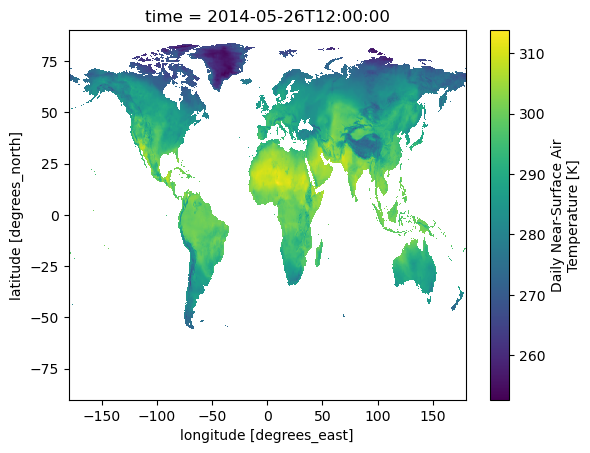

In [15]:
ds_model.tas.sel(time="2014-05-26").plot()